In [ ]:
##########################################  Fase II - Modelo de detección de fraude en seguros  #########################################

##################################  Instalación de dependencias, importar librerías, reproducibilidad  ##################################


%pip install -q kagglehub mlflow scikit-learn pandas numpy matplotlib seaborn joblib imbalanced-learn cloudpickle


import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import kagglehub
import mlflow
import mlflow.sklearn
import shutil

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Semilla para reproducibilidad
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)

# Directorios de trabajo
BASE_DIR = Path("/content/sentinel")
BASE_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACTS_DIR = BASE_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)

print("Entorno configurado correctamente.")


Entorno configurado correctamente.


Using Colab cache for faster access to the 'vehicle-claim-fraud-detection' dataset.
Dataset descargado correctamente. /kaggle/input/vehicle-claim-fraud-detection

Archivos CSV encontrados:
- fraud_oracle.csv

Cargando archivo: fraud_oracle.csv

Dimensiones: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


Número de registros: 15420
Número de columnas: 33

Columnas:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-nu

,0
Month,0
WeekOfMonth,0
DayOfWeek,0
Make,0
AccidentArea,0
DayOfWeekClaimed,0
MonthClaimed,0
WeekOfMonthClaimed,0
Sex,0
MaritalStatus,0



Registros duplicados:
0
Distribución de clases:


,count
FraudFound_P,
0,14497
1,923


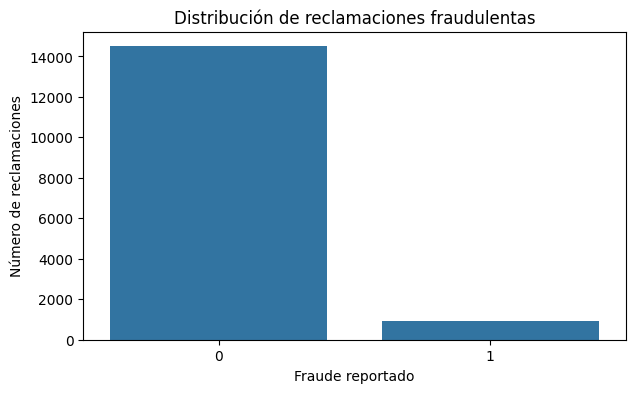

In [ ]:
###############################################  Descarga y análisis de dataset de Kaggle  ##############################################

# Descarga del dataset público desde Kaggle
dataset_path = kagglehub.dataset_download("shivamb/vehicle-claim-fraud-detection")
print("Dataset descargado correctamente.", dataset_path)

# Identificar archivos CSV disponibles
csv_files = list(Path(dataset_path).rglob("*.csv"))

print("\nArchivos CSV encontrados:")
for archivo in csv_files:
    print("-", archivo.name)

if not csv_files:
    raise FileNotFoundError("No se encontró ningún archivo CSV en la descarga de Kaggle.")

# Buscar el archivo de reclamaciones de forma más flexible
matches = [
    archivo for archivo in csv_files
    if archivo.name.lower() == "fraud_oracle.csv"
]

# Si no hay coincidencia flexible, usar el primer CSV encontrado
if not matches:
    archivo_final = next((a for a in csv_files if a.name.lower() == "fraud_oracle.csv"), None)
    if archivo_final is None:
        raise FileNotFoundError("No se encontró fraud_oracle.csv")
else:
    archivo_final = matches[0]

print(f"\nCargando archivo: {archivo_final.name}")

# Cargar los datos en un DataFrame
df = pd.read_csv(archivo_final)

# Dimensiones y muestra del dataset
print("\nDimensiones:", df.shape)
display(df.head())

# Inspección de la estructura del dataset
print("Número de registros:", len(df))
print("Número de columnas:", len(df.columns))

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
df.info()

print("\nValores faltantes:")
display(df.isna().sum().sort_values(ascending=False).head(20))

print("\nRegistros duplicados:")
print(df.duplicated().sum())

# La columna FraudFound_P indica si una reclamación fue fraudulenta
TARGET = "FraudFound_P"

if TARGET not in df.columns:
    raise ValueError(
        f"No se encontró la columna objetivo: {TARGET}"
    )

print("Distribución de clases:")
display(df[TARGET].value_counts(dropna=False))

# Visualización de la distribución
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x=TARGET,
    order=df[TARGET].value_counts().index
)

plt.title("Distribución de reclamaciones fraudulentas")
plt.xlabel("Fraude reportado")
plt.ylabel("Número de reclamaciones")
plt.show()

In [ ]:
##########################################################  Limpieza de datos  ##########################################################

# Copia del dataset original
data = df.copy()

# Convertir signos de interrogación en valores faltantes
data = data.replace("?", np.nan)

# Eliminar duplicados
data = data.drop_duplicates().reset_index(drop=True)

# Validar que únicamente contiene valores 0 y 1
assert not data[TARGET].isna().any(), "La variable objetivo contiene valores faltantes"
assert set(data[TARGET].unique()) == {0, 1}, "La variable objetivo debe contener valores 0 y 1"

print("Dimensiones después de limpieza:", data.shape)
display(data.head())



Dimensiones después de limpieza: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [ ]:
###############################################  Preparación, entrenamiento, validación  ################################################

# Excluir columnas
columnas_excluir = [
    "policy_number",
    "insured_zip",
    "incident_location",
    "_c39",
    "auto_model",
    "policy_bind_date",
    "incident_date",
    "total_claim_amount",
    "injury_claim",
    "property_claim",
    "vehicle_claim"
]

X = data.drop(columns=[TARGET] + columnas_excluir, errors="ignore")
y = data[TARGET]

print("Variables predictoras:", X.shape[1])
print("Registros:", X.shape[0])

print("\nVariables utilizadas:")
print(X.columns.tolist())

# Separación para entrenamiento y pruebas
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nProporción de fraude:")
print("Train:", y_train.mean())
print("Validación:", y_val.mean())
print("Test:", y_test.mean())


# Identificar variables numéricas y categóricas
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Pipeline numérico
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

# Pipeline categórico
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Transformación completa
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features), ("cat", categorical_transformer, categorical_features)])

print("Variables numéricas:", len(numeric_features))
print("Variables categóricas:", len(categorical_features))


Variables predictoras: 32
Registros: 15420

Variables utilizadas:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']
Entrenamiento: (9252, 32)
Validación: (3084, 32)
Prueba: (3084, 32)

Proporción de fraude:
Train: 0.05987894509295288
Validación: 0.05998702983138781
Test: 0.05966277561608301
Variables numéricas: 8
Variables categóricas: 24


In [ ]:
######################################################  Configurar MLFlow y modelos  ####################################################

# Directorio de trabajo
BASE_DIR = Path("/content/sentinel")
BASE_DIR.mkdir(parents=True, exist_ok=True)

# Directorio para artefactos
ARTIFACTS_DIR = BASE_DIR / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Base de datos SQLite para almacenar la información de los experimentos
DB_PATH = BASE_DIR / "mlflow.db"
MLFLOW_TRACKING_URI = f"sqlite:///{DB_PATH}"

# Configurar MLflow y experimento
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
EXPERIMENT_NAME = "Sentinel_Fraud_Detection"
mlflow.set_experiment(EXPERIMENT_NAME)

# Configuración
print("MLflow configurado correctamente.")
print("Base de datos:", DB_PATH)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", EXPERIMENT_NAME)


def calcular_metricas(y_real, probabilidades, umbral=0.5):

    # Convertir probabilidades en clasificaciones
    predicciones = (np.asarray(probabilidades) >= umbral).astype(int)

    # Matriz de confusión
    tn, fp, fn, tp = confusion_matrix(y_real, predicciones, labels=[0, 1]).ravel()

    # Calcular métricas
    metricas = {
        "accuracy": accuracy_score(y_real, predicciones),
        "precision": precision_score(y_real, predicciones, zero_division=0),
        "recall": recall_score(y_real, predicciones, zero_division=0),
        "f1": f1_score(y_real, predicciones, zero_division=0),
        "roc_auc": roc_auc_score(y_real, probabilidades),
        "pr_auc": average_precision_score(y_real, probabilidades),
        "fpr": fp / (fp + tn) if (fp + tn) else 0,
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn)
    }

    return metricas

# Definir modelos a comparar
experimentos = {
    "Logistic_Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),

    "Random_Forest_Base": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=2, random_state=SEED, n_jobs=-1),

    "Random_Forest_Balanced": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=3,
                                                     class_weight="balanced", random_state=SEED, n_jobs=-1)
}

print("Experimentos definidos:")
for nombre in experimentos:
    print("-", nombre)


MLflow configurado correctamente.
Base de datos: /content/sentinel/mlflow.db
Tracking URI: sqlite:////content/sentinel/mlflow.db
Experimento: Sentinel_Fraud_Detection
Experimentos definidos:
- Logistic_Regression
- Random_Forest_Base
- Random_Forest_Balanced


In [ ]:
##############################################  Entrenamiento y registro de experimentos  ###############################################

# Entrenar los modelos y registrar resultados
modelos_entrenados = {}
resultados = []

for nombre, clasificador in experimentos.items():
    print(f"\nEntrenando: {nombre}")
    pipeline = Pipeline([("preprocessor", preprocessor), ("classifier", clasificador)])

    with mlflow.start_run(run_name=nombre):
        # Registrar configuración
        mlflow.log_param("modelo", nombre)
        mlflow.log_param("seed", SEED)
        mlflow.log_param("train_size", len(X_train))
        mlflow.log_param("validation_size", len(X_val))
        mlflow.log_params(clasificador.get_params())

        # Entrenamiento
        pipeline.fit(X_train, y_train)

        # Probabilidades de fraude
        probabilidades = pipeline.predict_proba(X_val)[:, 1]

        # Evaluación inicial con umbral 0.5
        metricas = calcular_metricas(y_val, probabilidades, umbral=0.5)

        # Registrar métricas
        mlflow.log_metrics({
            k: float(v)
            for k, v in metricas.items()
        })

        # Registrar el modelo
        mlflow.sklearn.log_model(sk_model=pipeline, artifact_path="modelo", serialization_format="cloudpickle")


        modelos_entrenados[nombre] = {"pipeline": pipeline, "probabilidades": probabilidades}
        resultados.append({"modelo": nombre, **metricas})

        print("Precision:", round(metricas["precision"], 4))
        print("Recall:", round(metricas["recall"], 4))
        print("FPR:", round(metricas["fpr"], 4))

print("\nEntrenamiento finalizado.")



Entrenando: Logistic_Regression


2026/10/29 03:06:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/29 03:06:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Precision: 0.1305
Recall: 0.8486
FPR: 0.3608

Entrenando: Random_Forest_Base


2026/10/29 03:06:58 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/29 03:06:58 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Precision: 0.0
Recall: 0.0
FPR: 0.0

Entrenando: Random_Forest_Balanced


2026/10/29 03:07:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/29 03:07:11 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Precision: 0.1706
Recall: 0.5892
FPR: 0.1828

Entrenamiento finalizado.


In [ ]:
#######################################################  Comparación de resultados  #####################################################

# Crear tabla comparativa

df_resultados = pd.DataFrame(resultados)

columnas = [
    "modelo",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc",
    "fpr"
]

display(df_resultados[columnas].round(4))

# Guardar evidencia
df_resultados.to_csv(ARTIFACTS_DIR / "comparacion_modelos.csv", index=False)



,modelo,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr
0,Logistic_Regression,0.6518,0.1305,0.8486,0.2262,0.8006,0.1546,0.3608
1,Random_Forest_Base,0.9400,0.0000,0.0000,0.0000,0.8352,0.2779,0.0000
2,Random_Forest_Balanced,0.8035,0.1706,0.5892,0.2646,0.8251,0.2308,0.1828


In [ ]:
#########################################################  Análisis de desbalance  ######################################################

distribucion = y_train.value_counts()

porcentajes = (y_train.value_counts(normalize=True) * 100)

print("Distribución absoluta:")
display(distribucion)

print("\nDistribución porcentual:")
display(porcentajes.round(2))

# Relación entre clases
n_legitimos = (y_train == 0).sum()
n_fraudes = (y_train == 1).sum()

print("\nRelación legítimos/fraudes:", round(n_legitimos / n_fraudes, 2))

Distribución absoluta:


,count
FraudFound_P,
0,8698
1,554



Distribución porcentual:


,proportion
FraudFound_P,
0,94.01
1,5.99



Relación legítimos/fraudes: 15.7


In [ ]:
############################################################  Segunda iteración  ########################################################

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier)

from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV)

from sklearn.metrics import (average_precision_score, make_scorer)

print("Bibliotecas cargadas correctamente.")



Bibliotecas cargadas correctamente.


In [ ]:
######################################################  Definición de experimentos  #####################################################

# E4: Random Forest optimizado
rf_optimizado = RandomForestClassifier(
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)

# E5: Random Forest con SMOTE
# SMOTE se aplicará únicamente durante el entrenamiento.
rf_smote = RandomForestClassifier(
    random_state=SEED,
    n_jobs=-1
)

# E6: Extra Trees
extra_trees = ExtraTreesClassifier(
    random_state=SEED,
    class_weight="balanced",
    n_jobs=-1
)

print("Modelos definidos correctamente.")

Modelos definidos correctamente.


In [ ]:
######################################################  Pipelines de entrenamiento  #####################################################

# Random Forest
pipeline_rf = ImbPipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_optimizado)
])

# Random Forest con SMOTE
pipeline_smote = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=SEED)),
    ("classifier", rf_smote)
])

# Extra Trees
pipeline_extra = ImbPipeline([
    ("preprocessor", preprocessor),
    ("classifier", extra_trees)
])

print("Pipelines creados correctamente.")

Pipelines creados correctamente.


In [ ]:
#################################################  Optimización con validación cruzada  #################################################

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

parametros_rf = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__max_features": ["sqrt", "log2"]
}

parametros_smote = {
    "smote__sampling_strategy": [0.3, 0.5, 0.8],
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_leaf": [2, 5, 10]
}

parametros_extra = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_leaf": [1, 2, 5, 10]
}

experimentos_nuevos = {
    "RF_Optimizado": (
        pipeline_rf,
        parametros_rf
    ),
    "RF_SMOTE": (
        pipeline_smote,
        parametros_smote
    ),
    "Extra_Trees": (
        pipeline_extra,
        parametros_extra
    )
}

In [ ]:
##################################################  Entrenamiento y registro en MLflow  #################################################

import mlflow
import mlflow.sklearn
import pandas as pd

# Diccionarios para almacenar resultados
resultados_nuevos = []
modelos_nuevos = {}

# Ejecutar cada experimento
for nombre, (pipeline, parametros) in experimentos_nuevos.items():

    print(f"\nIniciando experimento: {nombre}")

    # Crear búsqueda de hiperparámetros
    busqueda = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=10,
        scoring="average_precision",
        cv=cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True
    )

    # Entrenar modelo
    busqueda.fit(X_train, y_train)

    # Recuperar mejor configuración
    mejor_modelo = busqueda.best_estimator_

    # Obtener probabilidades sobre validación
    probabilidades = mejor_modelo.predict_proba(X_val)[:, 1]

    # Calcular métricas
    metricas = calcular_metricas(y_val, probabilidades, umbral=0.5)

    # Registrar experimento en MLflow
    with mlflow.start_run(run_name=nombre):

        # Parámetros generales
        mlflow.log_params({
            "algoritmo": nombre,
            "cv_folds": 3,
            "n_iter": 10,
            "random_state": SEED
        })

        # Mejores hiperparámetros
        mlflow.log_params(busqueda.best_params_)

        # Métrica de validación cruzada
        mlflow.log_metric("cv_pr_auc", float(busqueda.best_score_))

        # Métricas de validación
        mlflow.log_metrics({
            f"val_{k}": float(v)
            for k, v in metricas.items()
        })

        # Registrar modelo usando cloudpickle
        mlflow.sklearn.log_model(
            sk_model=mejor_modelo,
            name="modelo",
            serialization_format="cloudpickle"
        )

    # Guardar modelo y probabilidades en memoria
    modelos_nuevos[nombre] = {
        "pipeline": mejor_modelo,
        "probabilidades": probabilidades
    }

    # Guardar resultados
    resultados_nuevos.append({
        "modelo": nombre,
        "cv_pr_auc": float(busqueda.best_score_),
        **metricas
    })

    print("PR-AUC CV:", round(busqueda.best_score_, 4))

    print("PR-AUC validación:", round(metricas["pr_auc"], 4)
    )

print("\nTodos los experimentos finalizaron.")


Iniciando experimento: RF_Optimizado


2026/10/29 03:08:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC CV: 0.2367
PR-AUC validación: 0.2741

Iniciando experimento: RF_SMOTE


2026/10/29 03:10:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC CV: 0.1831
PR-AUC validación: 0.2137

Iniciando experimento: Extra_Trees


2026/10/29 03:12:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


PR-AUC CV: 0.2231
PR-AUC validación: 0.2515

Todos los experimentos finalizaron.


In [ ]:
#########################################################  Evidencia de MLflow  #########################################################

runs = mlflow.search_runs(
    experiment_names=["Sentinel_Fraud_Detection"]
)

columnas = [
    "tags.mlflow.runName",
    "metrics.cv_pr_auc",
    "metrics.val_pr_auc",
    "metrics.val_precision",
    "metrics.val_recall",
    "metrics.val_fpr"
]

columnas_disponibles = [
    c for c in columnas if c in runs.columns
]

display(runs[columnas_disponibles])

,tags.mlflow.runName,metrics.cv_pr_auc,metrics.val_pr_auc,metrics.val_precision,metrics.val_recall,metrics.val_fpr
0,Extra_Trees,0.223103,0.251491,0.75,0.016216,0.000345
1,RF_SMOTE,0.183115,0.213725,0.00,0.000000,0.000000
2,RF_Optimizado,0.236715,0.274103,0.00,0.000000,0.000000
3,Random_Forest_Balanced,NaN,NaN,NaN,NaN,NaN
4,Random_Forest_Base,NaN,NaN,NaN,NaN,NaN
5,Logistic_Regression,NaN,NaN,NaN,NaN,NaN
6,Sentinel_Modelo_Final,NaN,NaN,NaN,NaN,NaN
7,Extra_Trees,0.223103,0.251491,0.75,0.016216,0.000345
8,RF_SMOTE,0.183115,0.213725,0.00,0.000000,0.000000
9,RF_Optimizado,0.236715,0.274103,0.00,0.000000,0.000000


In [ ]:
#######################################################  Optimización de umbrales  ######################################################

import numpy as np
import pandas as pd

# Evaluar umbrales entre 0.01 y 0.50
umbrales = np.arange(0.01, 0.501, 0.01)

resultados_umbral = []

for nombre, informacion in modelos_nuevos.items():

    probabilidades = informacion["probabilidades"]

    for umbral in umbrales:

        metricas = calcular_metricas(y_val, probabilidades, umbral)

        # Validar metas de Sentinel
        cumple = (
            metricas["precision"] > 0.60
            and metricas["recall"] > 0.85
            and metricas["fpr"] < 0.05
        )

        resultados_umbral.append({
            "Modelo": nombre,
            "Umbral": round(float(umbral), 2),
            "Precision": metricas["precision"],
            "Recall": metricas["recall"],
            "FPR": metricas["fpr"],
            "F1": metricas["f1"],
            "Cumple_KPI": cumple
        })

df_umbral = pd.DataFrame(resultados_umbral)

# Mostrar si alguna configuración cumple los KPI
print("Configuraciones que cumplen los KPI:")

display(
    df_umbral[df_umbral["Cumple_KPI"]]
)

# Buscar la configuración con mayor recall
# entre las que mantienen FPR inferior al 5%
candidatos = df_umbral[
    df_umbral["FPR"] < 0.05
].copy()

if candidatos.empty:
    print("Ningún umbral mantiene FPR inferior al 5%.")
else:
    mejores = (
        candidatos
        .sort_values(
            ["Recall", "Precision"],
            ascending=[False, False]
        )
        .groupby("Modelo", as_index=False)
        .first()
    )

    print("\nMejor umbral por modelo con FPR < 5%:")
    display(mejores.round(4))

# Guardar evidencia
df_umbral.to_csv(
    ARTIFACTS_DIR / "comparacion_umbrales_v2.csv",
    index=False
)
# Selección final: maximizar recall con FPR inferior a 5%;
# desempatar con precision y PR-AUC de validación.
mejores_candidatos = df_umbral[df_umbral["FPR"] < 0.05].copy()
if mejores_candidatos.empty:
    raise ValueError("Ningún modelo cumple la restricción de FPR en validación")
mejores_candidatos = mejores_candidatos.sort_values(
    ["Recall", "Precision", "F1"], ascending=[False, False, False]
)
seleccion = mejores_candidatos.iloc[0]
MEJOR_MODELO = seleccion["Modelo"]
MEJOR_UMBRAL = float(seleccion["Umbral"])
modelo_final = modelos_nuevos[MEJOR_MODELO]["pipeline"]
print("Modelo seleccionado:", MEJOR_MODELO, "| Umbral:", MEJOR_UMBRAL)


Configuraciones que cumplen los KPI:


,Modelo,Umbral,Precision,Recall,FPR,F1,Cumple_KPI



Mejor umbral por modelo con FPR < 5%:


,Modelo,Umbral,Precision,Recall,FPR,F1,Cumple_KPI
0,Extra_Trees,0.20,0.2784,0.2919,0.0483,0.2850,False
1,RF_Optimizado,0.19,0.2959,0.3135,0.0476,0.3045,False
2,RF_SMOTE,0.33,0.2486,0.2324,0.0448,0.2402,False


Modelo seleccionado: RF_Optimizado | Umbral: 0.19


RESULTADOS DE PRUEBA (exploratorios)


,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,tp,tn,fp,fn
0,0.9141,0.2834,0.288,0.2857,0.8438,0.2805,0.0462,53,2766,134,131


              precision    recall  f1-score   support

    Legítimo       0.95      0.95      0.95      2900
      Fraude       0.28      0.29      0.29       184

    accuracy                           0.91      3084
   macro avg       0.62      0.62      0.62      3084
weighted avg       0.91      0.91      0.91      3084



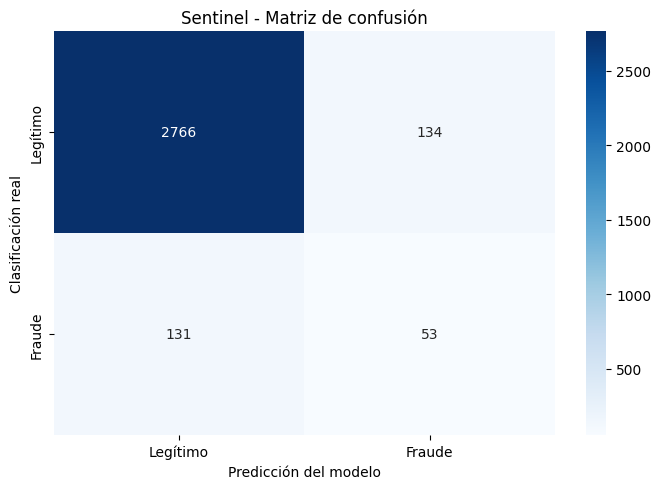

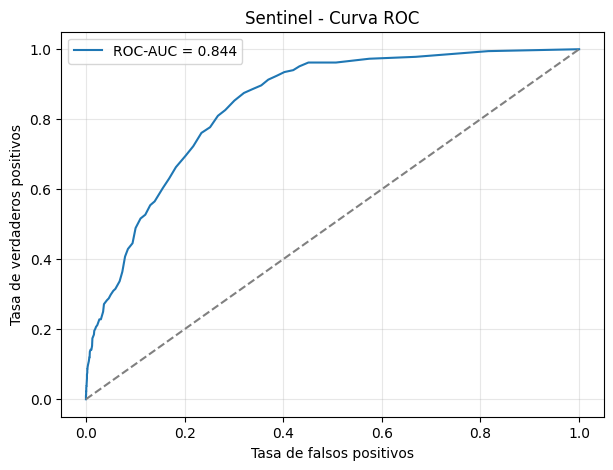

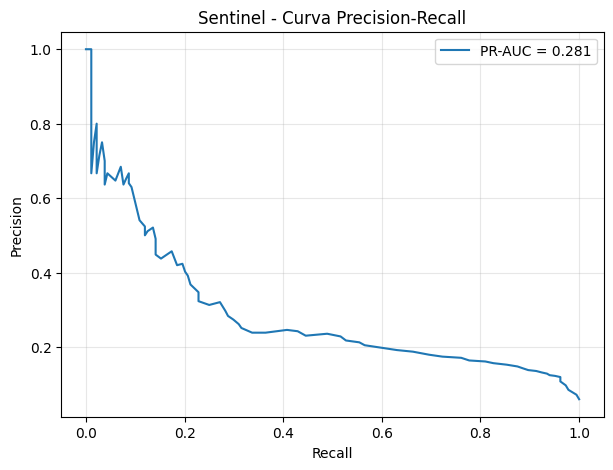

Variables más importantes:


,variable,importancia
11,Fault,0.130625
28,AddressChange_Claim,0.053387
15,PolicyNumber,0.045340
6,MonthClaimed,0.041309
17,Deductible,0.029487
0,Month,0.025464
31,BasePolicy,0.024769
30,Year,0.024007
10,Age,0.019772
13,VehicleCategory,0.013425


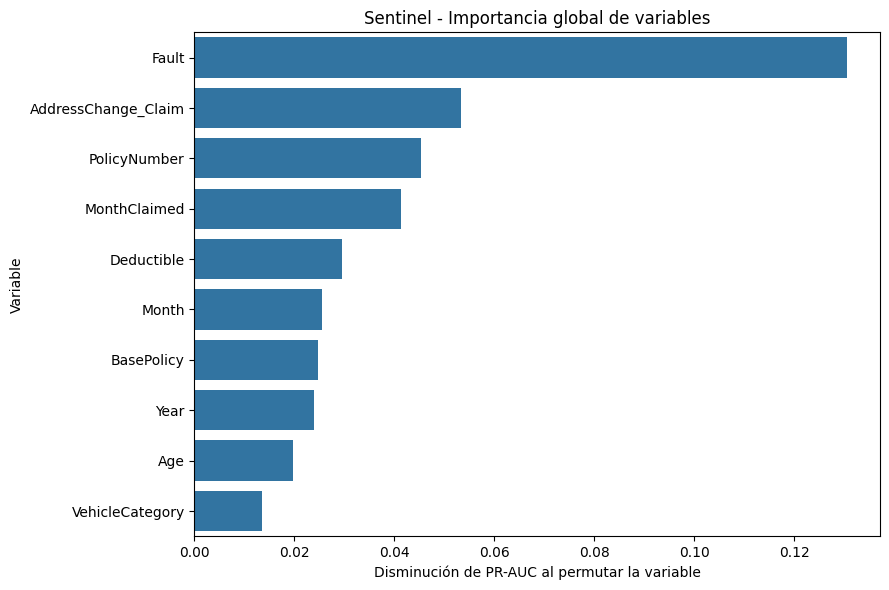

2026/10/29 03:13:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,tags.mlflow.runName,metrics.cv_pr_auc,metrics.val_pr_auc,metrics.val_recall
0,Sentinel_Modelo_Final,NaN,NaN,NaN
1,Extra_Trees,0.223103,0.251491,0.016216
2,RF_SMOTE,0.183115,0.213725,0.000000
3,RF_Optimizado,0.236715,0.274103,0.000000
4,Random_Forest_Balanced,NaN,NaN,NaN
5,Random_Forest_Base,NaN,NaN,NaN
6,Logistic_Regression,NaN,NaN,NaN
7,Sentinel_Modelo_Final,NaN,NaN,NaN
8,Extra_Trees,0.223103,0.251491,0.016216
9,RF_SMOTE,0.183115,0.213725,0.000000


Archivo generado: /content/Sentinel_Resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
################################################  Evaluación final y exportación del modelo  ################################################

probabilidades_test = modelo_final.predict_proba(X_test)[:, 1]
predicciones_test = (probabilidades_test >= MEJOR_UMBRAL).astype(int)
metricas_test = calcular_metricas(y_test, probabilidades_test, MEJOR_UMBRAL)

print("RESULTADOS DE PRUEBA (exploratorios)")
display(pd.DataFrame([metricas_test]).round(4))
print(classification_report(y_test, predicciones_test, target_names=["Legítimo", "Fraude"], zero_division=0))


#########################################################  Evidencias gráficas  #########################################################

# Matriz de confusión
matriz = confusion_matrix(y_test, predicciones_test, labels=[0, 1])
plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legítimo", "Fraude"],
    yticklabels=["Legítimo", "Fraude"]
)

plt.title("Sentinel - Matriz de confusión")
plt.xlabel("Predicción del modelo")
plt.ylabel("Clasificación real")
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "matriz_confusion.png", dpi=150)
plt.show()


# Curva ROC
fpr_curve, tpr_curve, _ = roc_curve(y_test, probabilidades_test)
plt.figure(figsize=(7, 5))
plt.plot(fpr_curve, tpr_curve, label=f"ROC-AUC = {metricas_test['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Sentinel - Curva ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(ARTIFACTS_DIR / "curva_roc.png", dpi=150)
plt.show()


# Curva Precision Recall
precision_curve, recall_curve, _ = (precision_recall_curve(y_test, probabilidades_test))
plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {metricas_test['pr_auc']:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Sentinel - Curva Precision-Recall")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(ARTIFACTS_DIR / "curva_precision_recall.png", dpi=150)
plt.show()


######################################################  Explicabilidad del modelo  ######################################################

# Medir la importancia de las variables originales usando el conjunto de validación.

importancia = permutation_importance(
    modelo_final,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1
)

df_importancia = pd.DataFrame({"variable": X_val.columns, "importancia": importancia.importances_mean})
df_importancia = df_importancia.sort_values("importancia", ascending=False)

print("Variables más importantes:")
display(df_importancia.head(10))
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df_importancia.head(10),
    x="importancia",
    y="variable"
)

plt.title("Sentinel - Importancia global de variables")
plt.xlabel("Disminución de PR-AUC al permutar la variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "importancia_variables.png", dpi=150)
plt.show()

# Guardar pipeline y metadatos calculados automáticamente.
joblib.dump(modelo_final, ARTIFACTS_DIR / "sentinel_pipeline.joblib")
metadata = {
    "proyecto": "Sentinel",
    "modelo": str(MEJOR_MODELO),
    "umbral_alerta": float(MEJOR_UMBRAL),
    "variable_objetivo": TARGET,
    "variables_entrada": X_train.columns.tolist(),
    "metricas_validacion": {k: float(seleccion[k]) for k in ["Precision", "Recall", "FPR", "F1"]},
    "metricas_prueba_exploratoria": {k: float(v) for k, v in metricas_test.items()},
    "requiere_revision_humana": True,
    "apto_para_produccion": False
}
with open(ARTIFACTS_DIR / "sentinel_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

# Prueba de carga del artefacto y predicción reproducible.
modelo_cargado = joblib.load(ARTIFACTS_DIR / "sentinel_pipeline.joblib")
assert np.allclose(modelo_cargado.predict_proba(X_val.iloc[:5]), modelo_final.predict_proba(X_val.iloc[:5]))

# Registro de la selección definitiva en MLflow.
with mlflow.start_run(run_name="Sentinel_Modelo_Final"):
    mlflow.log_param("modelo_seleccionado", str(MEJOR_MODELO))
    mlflow.log_param("umbral_alerta", float(MEJOR_UMBRAL))
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in metricas_test.items()})
    mlflow.log_artifacts(str(ARTIFACTS_DIR), artifact_path="evidencias")
    mlflow.sklearn.log_model(sk_model=modelo_final, name="modelo_final", serialization_format="cloudpickle")

experimentos_mlflow = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
experimentos_mlflow.to_csv(ARTIFACTS_DIR / "historial_mlflow.csv", index=False)
display(experimentos_mlflow[[c for c in ["tags.mlflow.runName", "metrics.cv_pr_auc", "metrics.val_pr_auc", "metrics.val_recall"] if c in experimentos_mlflow.columns]])

# Descargar ZIP de evidencias.
from google.colab import files
ruta_zip = shutil.make_archive("/content/Sentinel_Resultados", "zip", root_dir=BASE_DIR)
print("Archivo generado:", ruta_zip)
files.download(ruta_zip)


In [ ]:
# ============================================================
# SENTINEL - GENERAR RECLAMACIÓN DE PRUEBA PARA FASTAPI
# ============================================================

import json
from google.colab import files

# Seleccionar una reclamación del conjunto de validación
ejemplo = X_val.iloc[0].to_dict()

# Convertir valores NumPy a tipos compatibles con JSON
ejemplo = {
    clave: (
        valor.item()
        if hasattr(valor, "item")
        else valor
    )
    for clave, valor in ejemplo.items()
}

# Crear estructura esperada por FastAPI
solicitud = {
    "datos": ejemplo
}

# Guardar archivo JSON
with open(
    "/content/ejemplo_reclamacion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        solicitud,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Reclamación de prueba generada:")
print(json.dumps(solicitud, indent=4, ensure_ascii=False))

# Descargar archivo
files.download("/content/ejemplo_reclamacion.json")